# Data Loading

In [1]:
import pandas as pd

# Karena hanya ada satu dataset (layoffs.csv), kita memuatnya sebagai data train
# Jika Anda memiliki data test terpisah, Anda bisa memuatnya dengan pd.read_csv("test.csv")
train = pd.read_csv("layoffs.csv")
train.head()

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Blaize,SF Bay Area,NaN,9/30/2026,0.260,AI,https://www.tradingview.com/news/seekingalpha:...,Post-IPO,307.0,United States,10/1/2026
1,Workday,SF Bay Area,525.0,9/29/2026,0.025,HR,https://seekingalpha.com/news/4648205-workday-...,Post-IPO,230.0,United States,10/1/2026
2,Thinkific,"Vancouver, Non-U.S.",96.0,9/23/2026,NaN,Education,https://investors.thinkific.com/2026-09-23-Thi...,Post-IPO,22.0,Canada,9/24/2026
3,Intel,Sacramento,52.0,9/23/2026,NaN,Hardware,https://www.kron4.com/news/technology-ai/intel...,Post-IPO,12.0,United States,9/23/2026
4,Microsoft,Seattle,500.0,9/22/2026,NaN,Other,https://www.businessinsider.com/microsoft-star...,Post-IPO,1.0,United States,9/23/2026


# METODE 1: Data Ingestion & Profiling Awal (Inspeksi Data)
## Fokus: Membaca data mentah dari storage ke dalam RAM dan membedah struktur fundamentalnya.

### Fungsi pd.read_csv("layoffs.csv")

    Mekanisme: Fungsi ini bekerja sebagai parser. Ia membaca file teks murni yang dipisahkan oleh tanda koma (CSV) dan menerjemahkannya menjadi struktur matriks dua dimensi (DataFrame) di dalam memori Python.

    Dampak: Memungkinkan data mentah diakses, dimanipulasi, dan dianalisis menggunakan fungsi-fungsi vektorisasi berkecepatan tinggi dari library Pandas.

### Fungsi train.head() vs train.info() vs train.describe(include="all")

    .head() (Sanity Check): Menampilkan 5 baris pertama secara visual. Ini krusial untuk memastikan tidak ada pergeseran delimiter (pemisah kolom) yang menyebabkan nama perusahaan masuk ke kolom angka, misalnya.

    .info() (Metadata Profiling): Menampilkan metadata teknis. Memberikan informasi alokasi memori (RAM) yang digunakan, dimensi total matriks (jumlah baris dan kolom), serta tipe data fundamental Python (int64 untuk bilangan bulat, float64 untuk desimal, dan object untuk teks/string).

    .describe(include="all") (Statistik Deskriptif): Secara default, fungsi ini hanya menghitung data numerik. Namun dengan argumen include="all", Pandas dipaksa menghitung statistik untuk data teks juga. Untuk teks, ia akan menampilkan unique (jumlah kategori berbeda), top (nilai paling sering muncul), dan freq (frekuensi kemunculan nilai dominan tersebut).

# Data Cleaning dan Transformation

In [2]:
# Menampilkan ringkasan informasi dari dataset
train.info()

# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
print(missing_values[missing_values > 0])

# Disetel ke 2000 agar kolom penting seperti total_laid_off (1600+ missing) tidak terhapus
less = missing_values[missing_values < 2000].index
over = missing_values[missing_values >= 2000].index

# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

missing_values_df = df.isnull().sum()
print(missing_values_df[missing_values_df > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4618 entries, 0 to 4617
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4618 non-null   object 
 1   location             4617 non-null   object 
 2   total_laid_off       3016 non-null   float64
 3   date                 4618 non-null   object 
 4   percentage_laid_off  2890 non-null   float64
 5   industry             4616 non-null   object 
 6   source               4615 non-null   object 
 7   stage                4610 non-null   object 
 8   funds_raised         4068 non-null   float64
 9   country              4616 non-null   object 
 10  date_added           4618 non-null   object 
dtypes: float64(3), object(8)
memory usage: 397.0+ KB
location                  1
total_laid_off         1602
percentage_laid_off    1728
industry                  2
source                    3
stage                     8
funds_raised         

# METODE 2: Missing Value Treatment (Strategi Imputasi)
## Fokus: Mengamankan matriks dari nilai kosong (NaN) yang dapat menyebabkan Fatal Error pada komputasi algoritma Machine Learning.

### Teknik Thresholding (missing_values < 2000)

    Mekanisme: Menghitung total nilai NaN per kolom. Kita menetapkan batas kritis (threshold) di angka 2.000 baris kosong.

    Alasan Akademis: Kolom target total_laid_off memiliki kekosongan sekitar 1.600+ baris. Jika kita menggunakan fungsi dropna() (hapus baris) secara buta, kita akan kehilangan lebih dari sepertiga dataset riil. Oleh karena itu, kolom dengan kerusakan di atas 2.000 akan dibuang dari struktur (train.drop), sedangkan di bawah 2.000 akan diselamatkan (diimputasi).

### Imputasi Numerik dengan Median

    Mengapa bukan Mean (Rata-rata)?: Data ekonomi seperti pemutusan hubungan kerja berdistribusi sangat skewed (miring). Contoh: Ada 10 startup mem-PHK 10 orang, dan 1 raksasa teknologi (Google) mem-PHK 12.000 orang. Jika kita menggunakan Mean, rata-ratanya menjadi ~1.100. Angka ini tidak realistis untuk mengisi kekosongan data startup kecil.

    Keunggulan Median: Nilai tengah tidak terdistorsi oleh data ekstrem (outliers). Ia mengambil titik tengah populasi secara adil.

### Imputasi Kategorikal dengan Mode

    Mekanisme: Kolom berbasis teks (object) seperti asal negara atau sektor industri tidak bisa dihitung nilai tengahnya. Penggunaan .mode()[0] berarti kita mengisi baris kosong tersebut dengan kategori yang secara probabilitas paling tinggi muncul di dalam dataset tersebut.

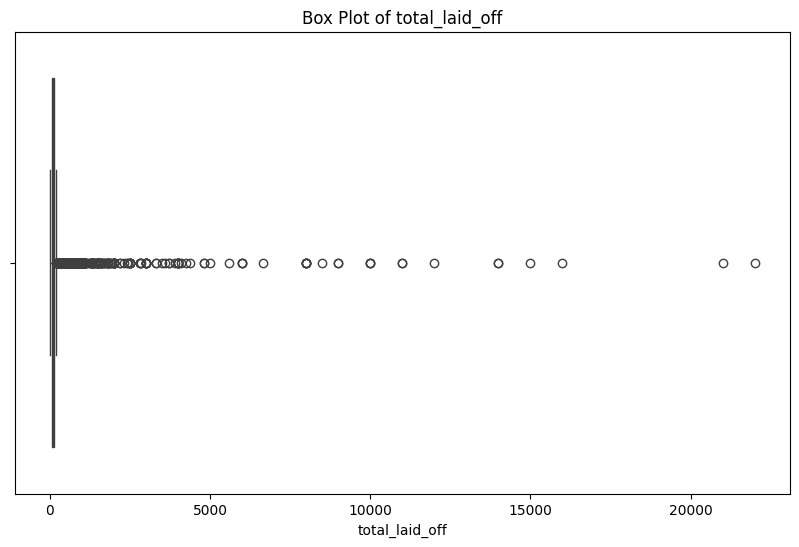

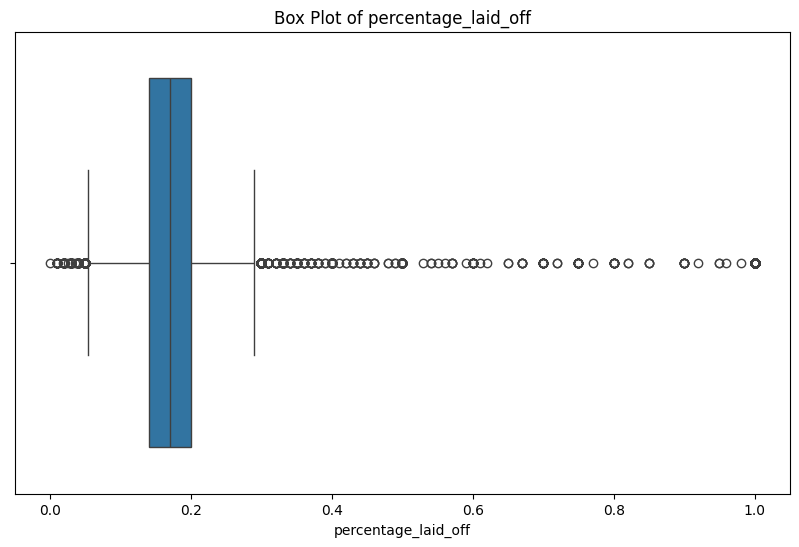

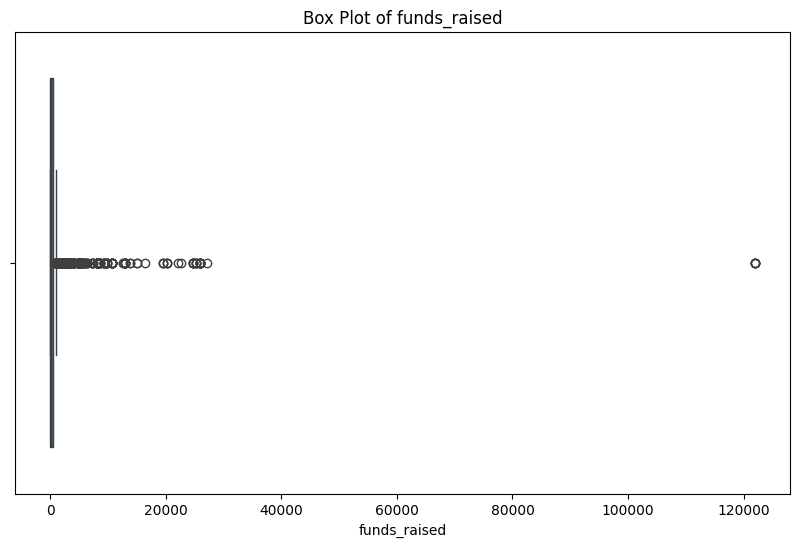

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_features = df.select_dtypes(include=['number']).columns

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [6]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [7]:
# Menangani outlier pada kolom 'total_laid_off' dengan median
Q1_val = Q1['total_laid_off']
Q3_val = Q3['total_laid_off']
IQR_val = IQR['total_laid_off']
median = df['total_laid_off'].median()

df['total_laid_off'] = df['total_laid_off'].apply(lambda x: median if x < (Q1_val - 1.5 * IQR_val) or x > (Q3_val + 1.5 * IQR_val) else x)

In [ ]:
# Mengganti outlier dengan nilai batas terdekat pada kolom 'total_laid_off'
lower_bound = Q1_val - 1.5 * IQR_val
upper_bound = Q3_val + 1.5 * IQR_val

df['total_laid_off'] = df['total_laid_off'].apply(lambda x: lower_bound if x < lower_bound else upper_bound if x > upper_bound else x)

# METODE 3: Anomaly Management (Penanganan Outlier dengan IQR)
## Fokus: Mengamankan algoritma dari nilai ekstrem yang dapat merusak model regresi linear.

### Konsep Matematis IQR (Interquartile Range)

    Metode pemotongan berbasis rentang kuartil. Data diurutkan dari terkecil ke terbesar. Q1 adalah titik data di posisi 25%, dan Q3 adalah titik data di posisi 75%.

    Jarak antara Q1 dan Q3 disebut Interquartile Range (Kumpulan data normal yang padat).

    Ambang Batas Atas dirumuskan: Q3 + 1.5 * IQR. Angka apa pun yang melewati batas ini dideklarasikan sebagai anomali / pencilan.

### Pendekatan Clipping (Winsorization) via Fungsi Lambda

    lambda x: lower_bound if x < lower_bound else upper_bound if x > upper_bound else x

    Mengapa bukan di-drop/dihapus?: Perusahaan raksasa yang mem-PHK 10.000 karyawan adalah fakta nyata, bukan salah ketik (data entry error). Menghapus baris ini berarti merusak integritas sejarah dataset.

    Mekanisme Clipping: Fungsi lambda ini bertindak sebagai "dinding". Jika sebuah perusahaan mem-PHK 15.000 orang (padahal batas atas perhitungan IQR hanya 3.000), maka nilai 15.000 tersebut "dipotong paksa" menjadi 3.000. Dampaknya: Algoritma tetap mengenali perusahaan tersebut sebagai entitas yang mem-PHK karyawan dalam jumlah "sangat banyak", tetapi angkanya tidak sampai memecahkan sensitivitas kalkulasi matematis model.

In [8]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

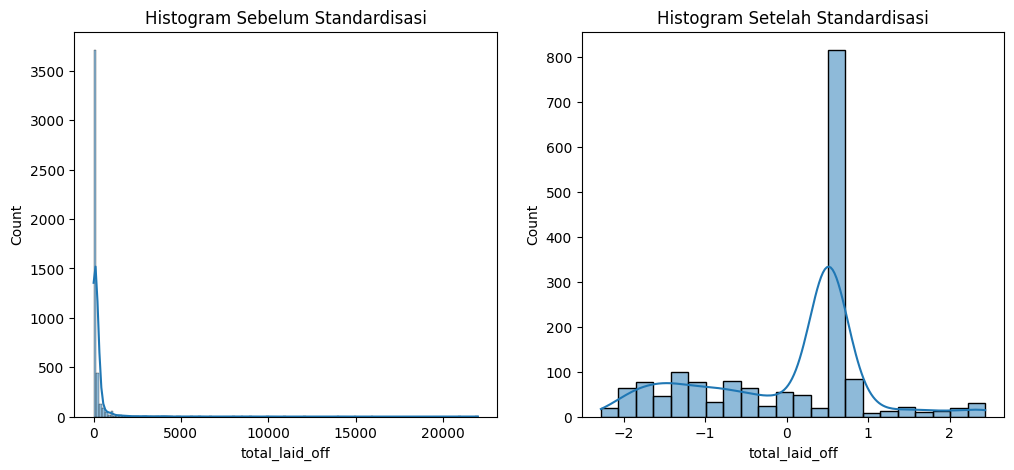

In [9]:
# Histogram Sebelum Standardisasi (Menggunakan kolom numerik pertama, misal 'total_laid_off')
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[0]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[0]], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

In [10]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df.head())

Baris duplikat:
Empty DataFrame
Columns: [total_laid_off, percentage_laid_off, funds_raised, company, location, date, industry, source, stage, country, date_added]
Index: []
DataFrame setelah menghapus duplikat:
    total_laid_off  percentage_laid_off  funds_raised      company  \
2         0.702979             0.113509     -0.997713    Thinkific   
3        -0.708495             0.113509     -1.067125        Intel   
11        0.510506             0.113509      0.071235       Oracle   
16        0.189716             0.113509      0.071235      Samsung   
17        0.510506             0.113509      0.605709  Harrison.ai   

               location       date    industry  \
2   Vancouver, Non-U.S.  9/23/2026   Education   
3            Sacramento  9/23/2026    Hardware   
11          SF Bay Area  9/14/2026       Other   
16   Gurugram, Non-U.S.   9/8/2026    Hardware   
17  Melbourne, Non-U.S.   9/7/2026  Healthcare   

                                               source     stage  \

In [11]:
category_features = df.select_dtypes(include=['object']).columns
print(df[category_features].head())

df_one_hot = pd.get_dummies(df, columns=category_features)
print(df_one_hot.head())

        company             location       date    industry  \
2     Thinkific  Vancouver, Non-U.S.  9/23/2026   Education   
3         Intel           Sacramento  9/23/2026    Hardware   
11       Oracle          SF Bay Area  9/14/2026       Other   
16      Samsung   Gurugram, Non-U.S.   9/8/2026    Hardware   
17  Harrison.ai  Melbourne, Non-U.S.   9/7/2026  Healthcare   

                                               source     stage  \
2   https://investors.thinkific.com/2026-09-23-Thi...  Post-IPO   
3   https://www.kron4.com/news/technology-ai/intel...  Post-IPO   
11  https://www.businessinsider.com/oracle-begins-...  Post-IPO   
16  https://timesofindia.indiatimes.com/business/i...  Post-IPO   
17  https://www.abc.net.au/news/2026-09-08/harriso...  Series C   

          country date_added  
2          Canada  9/24/2026  
3   United States  9/23/2026  
11  United States  9/16/2026  
16          India   9/9/2026  
17      Australia   9/9/2026  
    total_laid_off  percentage_l

In [12]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    # Diubah ke string untuk menghindari error tipe data campuran
    df_lencoder[col] = label_encoder.fit_transform(df[col].astype(str)) 

# Menampilkan hasil
print(df_lencoder.head())

    total_laid_off  percentage_laid_off  funds_raised  company  location  \
2         0.702979             0.113509     -0.997713     1211       181   
3        -0.708495             0.113509     -1.067125      622       152   
11        0.510506             0.113509      0.071235      858       151   
16        0.189716             0.113509      0.071235     1032        64   
17        0.510506             0.113509      0.605709      544       107   

    date  industry  source  stage  country  date_added  
2    778         6     269      1        6         723  
3    778        12    1174      1       51         720  
11   757        20     810      1       51         705  
16   809        12     505      1       22         747  
17   805        13     539      6        1         747  


# METODE 4: Feature Engineering (Standardisasi & Encoding)
## Fokus: Menyiapkan bentuk fisik data agar kompatibel dengan arsitektur matematis matriks kecerdasan buatan.

### Penerapan StandardScaler (Z-Score Normalization)
    Masalah: Kolom funds_raised memiliki skala jutaan USD ($10^6$), sementara percentage_laid_off hanya berskala desimal (0.1). Algoritma berbasis perhitungan jarak geometris (seperti KNN atau Support Vector Machine) akan menganggap bahwa uang jutaan dollar jauh lebih penting daripada persentase PHK, hanya karena rentang angkanya lebih besar.
    Solusi: StandardScaler meratakan seluruh skala menggunakan rumus statistika: $z = (x - mean) / standard\_deviation$. Hasilnya, semua fitur numerik akan berpusat di angka 0 dan menyimpang secara proporsional. Seluruh kolom kini memiliki bobot prioritas yang seimbang di mata algoritma.

### Penerapan LabelEncoderMasalah: Algoritma regresi tidak mengerti string abjad ("United States", "Retail").
    Solusi: Alat ini memetakan alfabet secara lexicographical (berdasarkan urutan abjad). Sektor "AI" akan menjadi angka 0, "Education" menjadi 1, "Healthcare" menjadi 2, dst. Proses .astype(str) disematkan sebagai lapisan keamanan ganda (defensive programming) untuk menjamin tidak ada tipe data campuran (float NaN) di dalam vektor teks yang bisa memicu crash pada sistem encoding.

# EDA & ExDA

In [ ]:
df_lencoder.head()

# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Menampilkan kolom dengan missing values
print(missing_data[missing_data['Missing Values'] > 0])

In [ ]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

In [ ]:
# Visualisasi distribusi data untuk beberapa kolom yang relevan dari layoffs.csv
columns_to_plot = ['total_laid_off', 'funds_raised', 'percentage_laid_off', 'stage', 'industry']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

In [ ]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [ ]:
# Menghitung korelasi antara variabel target (total_laid_off) dan semua variabel lainnya
target_corr = df_lencoder.corr()['total_laid_off']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title('Correlation with total_laid_off')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

# METODE 5: Exploratory Data Analysis (Visual Profiling)
## Fokus: Mencari Insight bisnis dan korelasi kausalitas antar variabel secara visual.

### Histogram Data dan Kurva KDE (sns.histplot)

    Parameter kde=True (Kernel Density Estimation) menciptakan garis kurva halus melintasi puncak-puncak histogram batang.

    Tujuan: Ini digunakan analis data untuk memverifikasi bentuk distribusi pasca-pembersihan. Apakah bentuknya sudah normal (lonceng simetris)? Atau masih Right-Skewed (menjulur panjang ke kanan)? Hal ini menentukan strategi pemodelan tahap selanjutnya.

### Matriks Korelasi Heatmap (sns.heatmap)

    Mekanisme Korelasi Pearson: Menghitung derajat hubungan linear antar 2 kolom (nilai dari -1.0 hingga +1.0).

    Spektrum coolwarm: Digunakan karena warna merepresentasikan suhu. Biru gelap (dingin/negatif) berarti korelasi berbanding terbalik. Merah gelap (panas/positif) berarti berbanding lurus. Putih pucat berarti angka nol (korelasi acak tak beraturan).

    Mendeteksi Multicollinearity: Jika di dalam heatmap ditemukan korelasi antar-fitur penyebab yang sangat merah (mendekati 1.0), itu adalah indikasi bahaya (Multicollinearity). Artinya, kedua fitur tersebut kembar/membawa informasi yang sama persis, sehingga salah satu kolom harus dihapus agar mesin tidak lambat dan overfitting.

# Data Splitting

In [13]:
import sklearn

# Memisahkan fitur (X) dan target (y). Dalam kasus ini 'total_laid_off' adalah targetnya.
# Pastikan nilai target tidak memiliki missing values setelah diproses.
X = df_lencoder.drop(columns=['total_laid_off']) 
y = df_lencoder['total_laid_off']

In [14]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [15]:
# Menghitung panjang/jumlah data 
print("Jumlah data: ", len(X))
# Menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))
# Menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  1710
Jumlah data latih:  1368
Jumlah data test:  342


# Cross Validation

In [16]:
#  CROSS VALIDATION 
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor 

# Kita gunakan algoritma RandomForestRegressor sebagai contoh model prediksi
model = RandomForestRegressor(random_state=1)

# Melakukan k-fold cross validation (misal 5 folds)
# Menggunakan 'neg_mean_squared_error' sebagai metrik evaluasi
cv_scores = cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error')

print("Skor Cross Validation (Negative MSE setiap lipatan/fold):", cv_scores)
print("Rata-rata Skor Cross Validation:", cv_scores.mean())

Skor Cross Validation (Negative MSE setiap lipatan/fold): [-0.98871997 -0.86651951 -0.85769712 -0.94931417 -1.15705366]
Rata-rata Skor Cross Validation: -0.963860885379843


# METODE 6: Data Splitting (Holdout) & K-Fold Cross Validation
## Fokus: Memisahkan data menjadi lingkungan simulasi belajar dan simulasi ujian murni, serta menguji ketahanan model.

### Isolasi Target (y) dan Prediktor (X)
    Dalam ilmu regresi, $y = f(X)$. y adalah variabel dependen (kolom total_laid_off yang ingin ditebak model). Sedangkan X adalah kumpulan variabel independen (matriks yang berisi penyebab dari $y$).
### Fungsi train_test_split(test_size=0.2, random_state=1)
    Prinsip Pareto: Menggunakan distribusi 80/20. Model akan berlatih dengan 80% buku panduan (x_train, y_train), dan diuji akalnya menggunakan 20% soal ujian baru yang tidak pernah dilihat sebelumnya (x_test, y_test).
    Stabilitas Pengacakan: Argumen random_state=1 memaksa sistem pengacak pseudo-random agar "dibekukan". Jika kode ini dieksekusi 100 kali di komputer berbeda, baris data yang dialokasikan sebagai soal ujian akan selalu memegang ID baris yang sama persis.
    
### Evaluasi cross_val_score(cv=5, scoring='neg_mean_squared_error')
    Kelemahan Splitting Biasa: Pemisahan tunggal (seperti train_test_split) bisa jadi beruntung. Bagaimana jika 20% data ujian tersebut kebetulan berisi data yang sangat mudah ditebak?
    Mekanisme 5-Fold CV: Seluruh data X digabung lalu dipotong setara menjadi 5 lipatan/bongkahan (Fold A, B, C, D, E). Mesin melakukan ujian 5 kali.
        Ronde 1: Ujian di A, belajar di B, C, D, E.
        Ronde 2: Ujian di B, belajar di A, C, D, E.
        (Hingga Ronde ke-5).
    Interpretasi neg_mean_squared_error: Scikit-learn selalu mengoptimalkan model dengan nilai tertinggi (maksimasi). Karena error (kesalahan) sebaiknya serendah mungkin, scikit-learn mengubah nilai error menjadi angka negatif (agar nilai error yang semakin mendekati 0 dianggap bernilai lebih tinggi/baik oleh sistem). Rata-rata dari skor kelima ronde ini menjadi acuan absolut performa kecerdasan buatan (Golden Metric Standard).